# 10 Joint relocation of the FMF detections with the 28 reference events

The 207 new FMF detections of the final catalog are relocated together with the 28 events of the 25 m reference, using the same HypoDD recipe as notebook 04 (decisions D21 and D22):
- **Picks.** Each detection inherits its template's P and S picks, shifted to the detection origin. These picks only place the cross-correlation windows.
- **Cross-correlation times.** 5–20 Hz, CC ≥ 0.7, at least 4 observations per pair, all event pairs.
- **Catalog differential times among the references only.** A detection is located by its waveform cross-correlation times alone; its inherited picks cannot pin it to its template's position.
- **Uncertainty.** A 1,000-replica bootstrap; then the 25 m rule (95 % half-widths ≤ 25 m in east, north and depth) applied to every event.

This notebook checks the solution, whether the 28 references stay where the DL-only relocation put them, how many detections meet the 25 m rule, and the combined geometry.

In [1]:
import os, sys, re
import numpy as np, pandas as pd
os.environ.setdefault('HELVETICA_DIR', '/home/msseo/Download/Helvetica')
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'
sys.path.insert(0, f'{DL}/pipeline')
import config, plotstyle  # noqa: F401
import matplotlib.pyplot as plt, matplotlib.dates as mdates
pd.set_option('display.width', 200)
RUN = f'{DL}/runs/hypodd_fmf'; BR = f'{RUN}/2.HypoDD/02.dt.cc'
allu = pd.read_csv(f'{DL}/catalogs/reference_25m_fmf/DL_all_with_uncertainty.csv', dtype={'event_id': str, 'template_event_id': str})
dlu = pd.read_csv(f'{DL}/catalogs/reference_25m/DL_all_with_uncertainty.csv', dtype={'event_id': str, 'template_match': str})
inp = pd.read_csv(f'{RUN}/fmf_relocation_input.csv', dtype={'event_id': str})
for d in (allu, dlu): d['t'] = pd.to_datetime(d['origin_time_reloc'] if 'origin_time_reloc' in d else d['origin_time'])
ML19 = '20251102203835'
def local(d, ref_id=ML19):
    o = d.set_index('event_id').loc[ref_id]; lat0, lon0, z0 = float(o.latitude), float(o.longitude), float(o.depth_km); d = d.copy()
    d['east'] = (d.longitude - lon0) * 111.19 * np.cos(np.radians(lat0)) * 1000; d['north'] = (d.latitude - lat0) * 111.19 * 1000; d['depth_m'] = (d.depth_km - z0) * 1000
    return d
allu, dlu = local(allu), local(dlu)
R, D = allu[allu.kind == 'reference'], allu[allu.kind == 'detection']
print(f'joint relocation: {len(allu)} events ({len(R)} references, {len(D)} detections) of {len(inp)} submitted')

joint relocation: 212 events (28 references, 184 detections) of 235 submitted


## 1. Data and conditioning

In [2]:
txt = open(f'{BR}/damping_calibration.txt').read(); last = re.findall(r'\{([^}]*)\}', txt)[-1]
cnd = {int(k): float(v) for k, v in (kv.split(':') for kv in last.split(','))}; cnd_ok = all(40 <= v <= 80 for v in cnd.values())
print('chosen DAMP per set:', re.search(r'chosen DAMP per set: \[([^\]]*)\]', txt).group(1)); print('condition number per set:', cnd, '| all within 40-80:', cnd_ok)
ct_det = int(D.ct_links.fillna(0).gt(0).sum())
print(f'catalog links: references median {R.ct_links.median():.0f}; detections with any catalog link: {ct_det} (expected 0 by design)')
print(f'cross-correlation links: references median {R.cc_links.median():.0f}; detections median {D.cc_links.median():.0f} (10th pct {D.cc_links.quantile(.1):.0f})')
lost = sorted(set(inp.event_id) - set(allu.event_id)); print(f'submitted but not relocated: {len(lost)}', lost[:10])

chosen DAMP per set: 66, 62, 54, 87, 76, 68, 58
condition number per set: {0: 66.2, 1: 77.7, 2: 71.1, 3: 68.8, 4: 71.2, 5: 72.0, 6: 73.3} | all within 40-80: True
catalog links: references median 580; detections with any catalog link: 0 (expected 0 by design)
cross-correlation links: references median 695; detections median 370 (10th pct 131)
submitted but not relocated: 23 ['20251102200518', '20251102200616', '20251102200642', '20251102200931', '20251102201201', '20251102201319', '20251102202330', '20251102202405', '20251102202621', '20251102202924']


## 2. Do the 28 references stay put?
Each reference event's position relative to the ML 1.9 is compared between the joint relocation and the DL-only relocation of notebook 04, after removing the median offset.

In [3]:
j = R.merge(dlu[['event_id', 'east', 'north', 'depth_m']], on='event_id', suffixes=('', '_dl'))
dd = j[['east', 'north', 'depth_m']].to_numpy() - j[['east_dl', 'north_dl', 'depth_m_dl']].to_numpy(); dd -= np.median(dd, axis=0)
ref_shift = pd.DataFrame(np.abs(dd), columns=['dE', 'dN', 'dZ']).describe(percentiles=[.5, .9]).loc[['50%', '90%', 'max']].round(1)
print(f'references matched: {len(j)} of {len(R)}'); display(ref_shift)

references matched: 28 of 28


,dE,dN,dZ
50%,1.4,1.1,1.0
90%,3.0,4.0,3.3
max,8.1,5.6,7.0


## 3. Uncertainties and the 25 m rule

,relocated,pass_25m,share,med_ex95,med_ey95,med_ez95
kind,,,,,,
references,28,28,1.0,1.8,1.3,1.2
detections,184,73,0.4,16.6,17.1,75.9


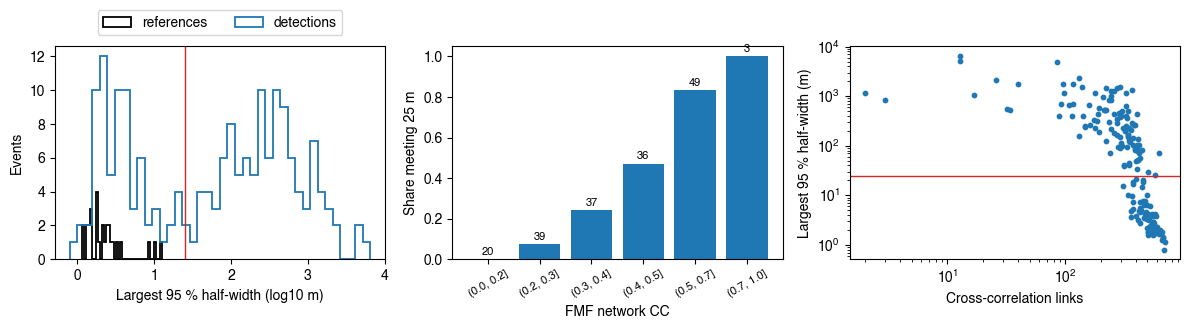

In [4]:
rows = []
for k, g in (('references', R), ('detections', D)):
    rows.append(dict(kind=k, relocated=len(g), pass_25m=int(g.pass25.sum()), share=round(g.pass25.mean(), 2), med_ex95=g.ex95.median(), med_ey95=g.ey95.median(), med_ez95=g.ez95.median()))
display(pd.DataFrame(rows).set_index('kind').round(1))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for k, g, col in (('references', R, 'black'), ('detections', D, 'tab:blue')):
    ax[0].hist(np.log10(g[['ex95', 'ey95', 'ez95']].max(axis=1).clip(lower=0.1)), bins=40, histtype='step', lw=1.3, color=col, label=k)
ax[0].axvline(np.log10(25), color='tab:red', lw=1); ax[0].set_xlabel('Largest 95 % half-width (log10 m)'); ax[0].set_ylabel('Events'); ax[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True)
b = pd.cut(D.fmf_cc, [0, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0]); s = D.groupby(b, observed=True).pass25.agg(['mean', 'size'])
ax[1].bar(range(len(s)), s['mean'], color='tab:blue'); ax[1].set_xticks(range(len(s)), [str(i) for i in s.index], rotation=30, fontsize=8); ax[1].set_ylabel('Share meeting 25 m'); ax[1].set_xlabel('FMF network CC')
for i, n in enumerate(s['size']): ax[1].text(i, s['mean'].iloc[i] + 0.02, str(n), ha='center', fontsize=8)
ax[2].scatter(D.cc_links, D[['ex95', 'ey95', 'ez95']].max(axis=1), s=10, color='tab:blue'); ax[2].set_xscale('log'); ax[2].set_yscale('log'); ax[2].axhline(25, color='tab:red', lw=1)
ax[2].set_xlabel('Cross-correlation links'); ax[2].set_ylabel('Largest 95 % half-width (m)')
plt.tight_layout(); plt.show()

## 4. Combined geometry (events meeting the 25 m rule)
Coordinates are relative to the relocated ML 1.9: east, north and depth in metres, with depth positive downward. Black outlines mark the references; color gives the origin time.

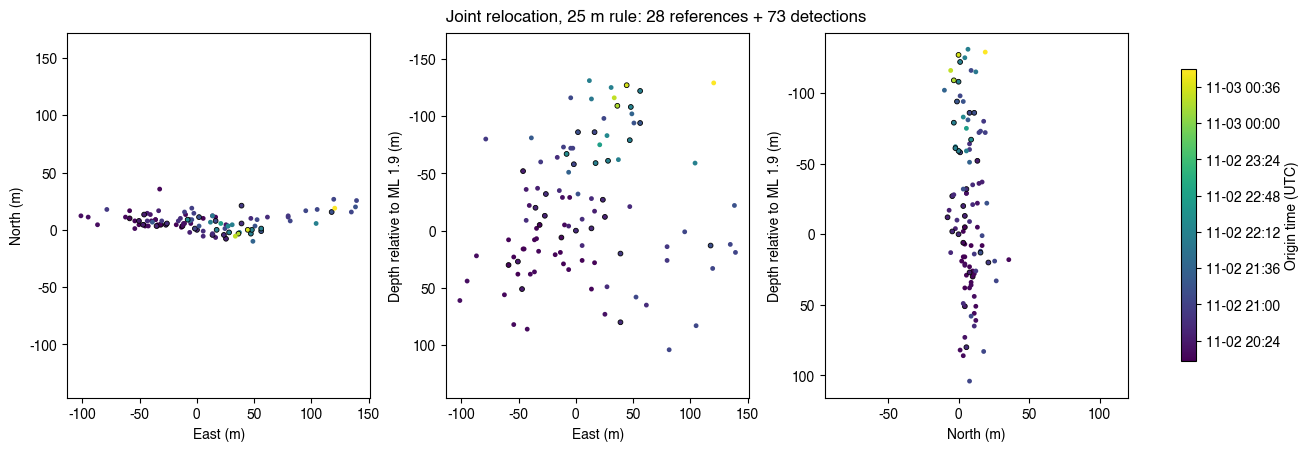

extent of 95 % of the events (m): {'east': 210, 'north': 29, 'depth_m': 209}


In [5]:
G = allu[allu.pass25].copy(); tnum = mdates.date2num(G.t); cm = plt.cm.viridis; norm = plt.Normalize(tnum.min(), tnum.max())
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4), layout='constrained')
for a, (x, y, xl, yl) in zip(ax, [('east', 'north', 'East (m)', 'North (m)'), ('east', 'depth_m', 'East (m)', 'Depth relative to ML 1.9 (m)'), ('north', 'depth_m', 'North (m)', 'Depth relative to ML 1.9 (m)')]):
    sc = a.scatter(G[x], G[y], c=tnum, cmap=cm, norm=norm, s=12, edgecolor=np.where(G.kind == 'reference', 'black', 'none'), linewidth=0.6, zorder=3)
    a.set_xlabel(xl); a.set_ylabel(yl); a.set_aspect('equal', adjustable='datalim')
    if 'depth' in y: a.invert_yaxis()
cb = fig.colorbar(sc, ax=ax, shrink=0.8, label='Origin time (UTC)'); cb.ax.yaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
fig.suptitle(f'Joint relocation, 25 m rule: {int((G.kind == "reference").sum())} references + {int((G.kind == "detection").sum())} detections'); plt.show()
ext = {c: float(G[c].quantile(.975) - G[c].quantile(.025)) for c in ('east', 'north', 'depth_m')}
print('extent of 95 % of the events (m):', {k: round(v) for k, v in ext.items()})

## 5. Fault plane (decision D15) with the detections included
The fit uses Haenam's total-least-squares SVD (`joint_science.plane`, copied verbatim, as in notebook 04), with 1,000 event resamples (seed 20260922). It reports the Haenam-convention 95 % ranges, the number of normal flips, and the normal-aligned ranges.

strike 268.7 / dip 88.2; RMS thickness 7.4 m; singular values [1.    0.826 0.124]; events 101
Haenam-convention 95 %: strike 267.0-270.8, dip 86.9-89.7; flips 4 of 1000
normals aligned: strike 267.1-270.9, dip 86.9-89.7


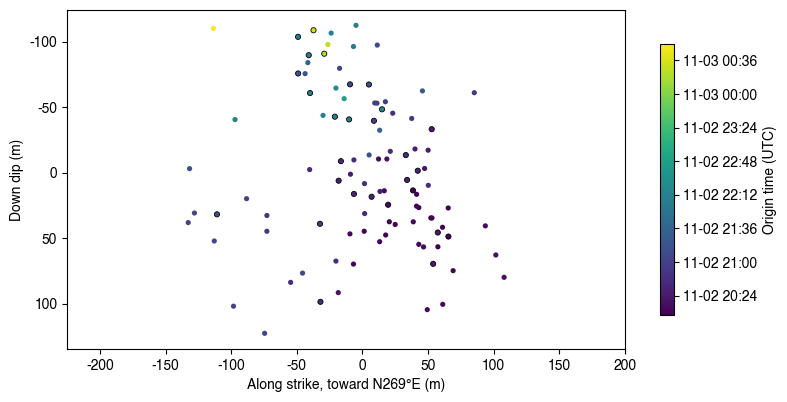

In [6]:
def plane(X):
    center=np.mean(X,axis=0);_,sv,v=np.linalg.svd(X-center,full_matrices=False);n=v[-1]
    if n[2]>0:n=-n
    dip=np.degrees(np.arccos(np.clip(-n[2],-1,1)));strike=(np.degrees(np.arctan2(n[0],n[1]))-90)%360
    s=np.array([np.sin(np.radians(strike)),np.cos(np.radians(strike)),0]);h=np.array([np.cos(np.radians(strike)),-np.sin(np.radians(strike)),0]);down=h*np.cos(np.radians(dip))+np.array([0,0,np.sin(np.radians(dip))])
    return dict(center=center,normal=n,strike=strike,dip=dip,s=s,h=h,down=down,rms=float(np.sqrt(np.mean(((X-center)@n)**2))),sv=sv)
X = G[['east', 'north', 'depth_m']].to_numpy(); p = plane(X); rng = np.random.default_rng(20260922)
bp = [plane(X[rng.integers(0, len(X), len(X))]) for _ in range(1000)]; boot = np.array([[b['strike'], b['dip']] for b in bp])
n_flip = int((np.abs((boot[:, 0] - p['strike'] + 180) % 360 - 180) > 90).sum())
al = np.array([b['normal'] * np.sign(b['normal'] @ p['normal']) for b in bp])
a_str = (np.degrees(np.arctan2(al[:, 0], al[:, 1])) - 90) % 360; a_str = p['strike'] + ((a_str - p['strike'] + 180) % 360 - 180); a_dip = np.degrees(np.arccos(np.clip(-al[:, 2], -1, 1)))
print(f'strike {p["strike"]:.1f} / dip {p["dip"]:.1f}; RMS thickness {p["rms"]:.1f} m; singular values {np.round(p["sv"] / p["sv"][0], 3)}; events {len(X)}')
print(f'Haenam-convention 95 %: strike {np.percentile(boot[:, 0], 2.5):.1f}-{np.percentile(boot[:, 0], 97.5):.1f}, dip {np.percentile(boot[:, 1], 2.5):.1f}-{np.percentile(boot[:, 1], 97.5):.1f}; flips {n_flip} of 1000')
print(f'normals aligned: strike {np.percentile(a_str, 2.5):.1f}-{np.percentile(a_str, 97.5):.1f}, dip {np.percentile(a_dip, 2.5):.1f}-{np.percentile(a_dip, 97.5):.1f}')
Y = X - p['center']; G['along'] = Y @ p['s']; G['down_dip'] = Y @ p['down']
fig, ax = plt.subplots(figsize=(9, 4.4))
sc = ax.scatter(G.along, G.down_dip, c=tnum, cmap=cm, norm=norm, s=14, edgecolor=np.where(G.kind == 'reference', 'black', 'none'), linewidth=0.6)
ax.invert_yaxis(); ax.set_aspect('equal', adjustable='datalim'); ax.set_xlabel(f'Along strike, toward N{p["strike"]:.0f}°E (m)'); ax.set_ylabel('Down dip (m)')
cb = fig.colorbar(sc, ax=ax, shrink=0.8, label='Origin time (UTC)'); cb.ax.yaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M')); plt.show()

## 6. Depth through the swarm

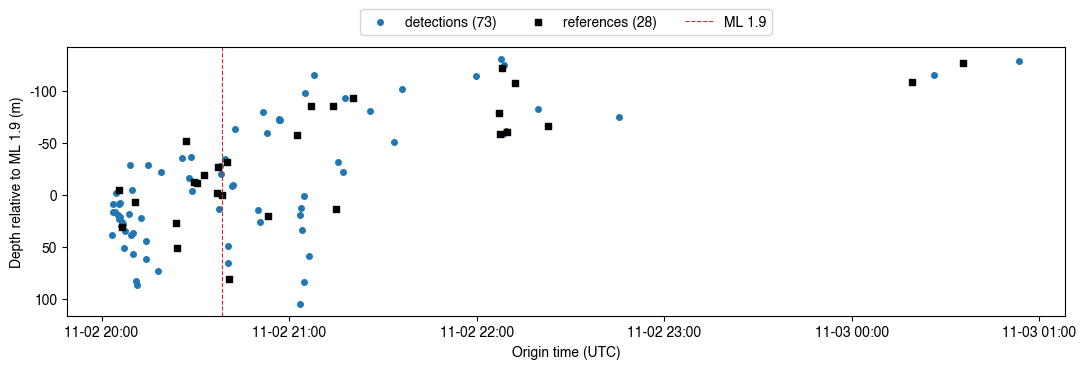

median depth relative to the ML 1.9: before +16 m (n=47), after -62 m (n=53); positive = deeper


In [7]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for k, col, mk in (('detection', 'tab:blue', 'o'), ('reference', 'black', 's')):
    g = G[G.kind == k]; ax.scatter(g.t, g.depth_m, s=16, color=col, marker=mk, label=f'{k}s ({len(g)})')
ax.axvline(pd.Timestamp('2025-11-02 20:38:35'), color='tab:red', lw=0.8, ls='--', label='ML 1.9')
ax.invert_yaxis(); ax.set_ylabel('Depth relative to ML 1.9 (m)'); ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M')); ax.set_xlabel('Origin time (UTC)')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=True); plt.tight_layout(); plt.show()
t19 = pd.Timestamp('2025-11-02 20:38:35'); b4, af = G[G.t < t19], G[G.t > t19 + pd.Timedelta(seconds=5)]
print(f'median depth relative to the ML 1.9: before {b4.depth_m.median():+.0f} m (n={len(b4)}), after {af.depth_m.median():+.0f} m (n={len(af)}); positive = deeper')

## 7. Bootstrap uncertainties in detail
Each event's uncertainty comes from 1,000 bootstrap replicas: the differential times are resampled with replacement and HypoDD is rerun from the main solution. The 95 % half-width on each axis is half the 2.5–97.5 % range of the replica positions.

This section shows:
- the half-widths in east, north and depth for references and detections;
- their cumulative distribution;
- the replica clouds of three example events.

10 %  25 %  50 %   75 %   90 %
references ex95   1.1   1.4   1.8    2.6    3.3
           ey95   0.9   1.1   1.3    2.1    2.5
           ez95   1.0   1.1   1.2    1.9    4.3
detections ex95   1.8   2.6  16.6  153.1  384.9
           ey95   1.5   2.8  17.1  199.2  425.8
           ez95   1.4   3.0  75.9  339.9  991.7

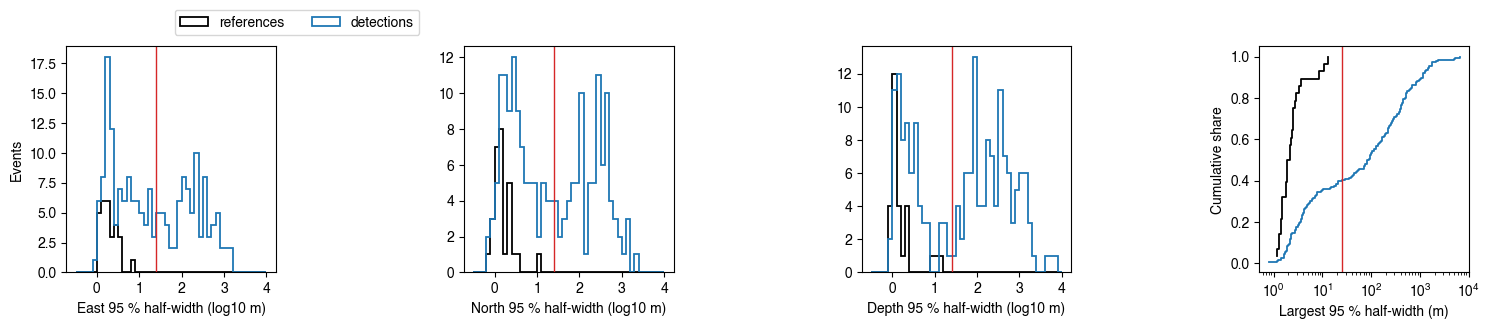

depth is the weakest axis for detections: median ez95 / median horizontal = 3.6; detections with depth as their largest half-width: 47 %


In [8]:
q = [0.1, 0.25, 0.5, 0.75, 0.9]
tabq = pd.concat({k: g[['ex95', 'ey95', 'ez95']].quantile(q).T for k, g in (('references', R), ('detections', D))}).round(1)
tabq.columns = [f'{int(x * 100)} %' for x in q]; display(tabq)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
bins = np.linspace(-0.5, 4, 46)
for a, c, lab in zip(ax[:3], ('ex95', 'ey95', 'ez95'), ('East', 'North', 'Depth')):
    for k, g, col in (('references', R, 'black'), ('detections', D, 'tab:blue')):
        a.hist(np.log10(g[c].clip(lower=0.3)), bins=bins, histtype='step', lw=1.3, color=col, label=k)
    a.axvline(np.log10(25), color='tab:red', lw=1); a.set_xlabel(f'{lab} 95 % half-width (log10 m)')
ax[0].set_ylabel('Events'); ax[0].legend(loc='lower center', bbox_to_anchor=(1.1, 1.02), ncol=2, frameon=True)
for k, g, col in (('references', R, 'black'), ('detections', D, 'tab:blue')):
    v = np.sort(g[['ex95', 'ey95', 'ez95']].max(axis=1).values); ax[3].step(v, np.arange(1, len(v) + 1) / len(v), where='post', color=col, lw=1.3)
ax[3].set_xscale('log'); ax[3].axvline(25, color='tab:red', lw=1); ax[3].set_xlabel('Largest 95 % half-width (m)'); ax[3].set_ylabel('Cumulative share')
plt.tight_layout(); plt.show()
print(f'depth is the weakest axis for detections: median ez95 / median horizontal = {D.ez95.median() / D[["ex95", "ey95"]].max(axis=1).median():.1f}; '
      f'detections with depth as their largest half-width: {int((D.ez95 >= D[["ex95", "ey95"]].max(axis=1)).mean() * 100)} %')

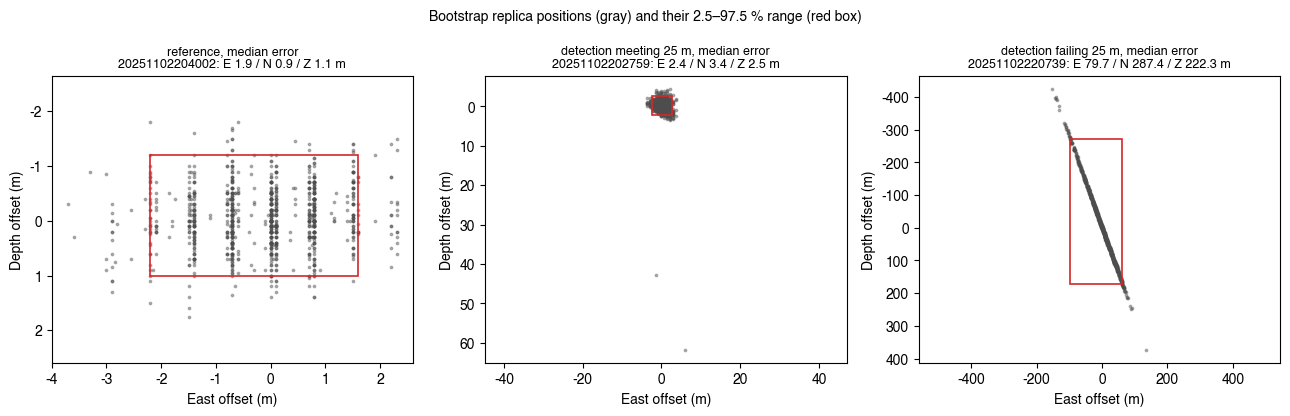

In [9]:
smp = np.load(f'{BR}/bootstrap_samples.npz')['data']
def cloud(eid):
    i = int(allu.set_index('event_id').loc[eid, 'id']); s = smp[smp[:, 0].astype(int) == i][:, 1:]
    return s - np.median(s, axis=0)
okD, badD = D[D.pass25], D[~D.pass25]
ex = [('reference, median error', R.iloc[(R.max95_m - R.max95_m.median()).abs().argsort().iloc[0]]),
      ('detection meeting 25 m, median error', okD.iloc[(okD.max95_m - okD.max95_m.median()).abs().argsort().iloc[0]]),
      ('detection failing 25 m, median error', badD.iloc[(badD.max95_m - badD.max95_m.median()).abs().argsort().iloc[0]])]
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
for a, (lab, r) in zip(ax, ex):
    c = cloud(r.event_id); a.scatter(c[:, 0], c[:, 2], s=3, color='0.3', alpha=0.4)
    lo, hi = np.percentile(c, 2.5, axis=0), np.percentile(c, 97.5, axis=0)
    a.add_patch(plt.Rectangle((lo[0], lo[2]), hi[0] - lo[0], hi[2] - lo[2], fill=False, ec='tab:red', lw=1.2))
    a.set_title(f'{lab}\n{r.event_id}: E {r.ex95:.1f} / N {r.ey95:.1f} / Z {r.ez95:.1f} m', fontsize=9)
    a.set_xlabel('East offset (m)'); a.set_ylabel('Depth offset (m)'); a.invert_yaxis(); a.set_aspect('equal', adjustable='datalim')
fig.suptitle('Bootstrap replica positions (gray) and their 2.5–97.5 % range (red box)', fontsize=10); plt.tight_layout(); plt.show()

## 8. The 25 m selection against all relocated events
**All events, colored by error.** All 212 relocated events are shown, colored by their largest 95 % half-width. Events beyond 25 m scatter around the sheet that the well-located events define.

**Sensitivity table.** The same quantities are recomputed for error bounds from 10 m to no limit:
- the number of events;
- the plane (Haenam method, 500 resamples) and its RMS thickness;
- the extent;
- the median depths before and after the ML 1.9.

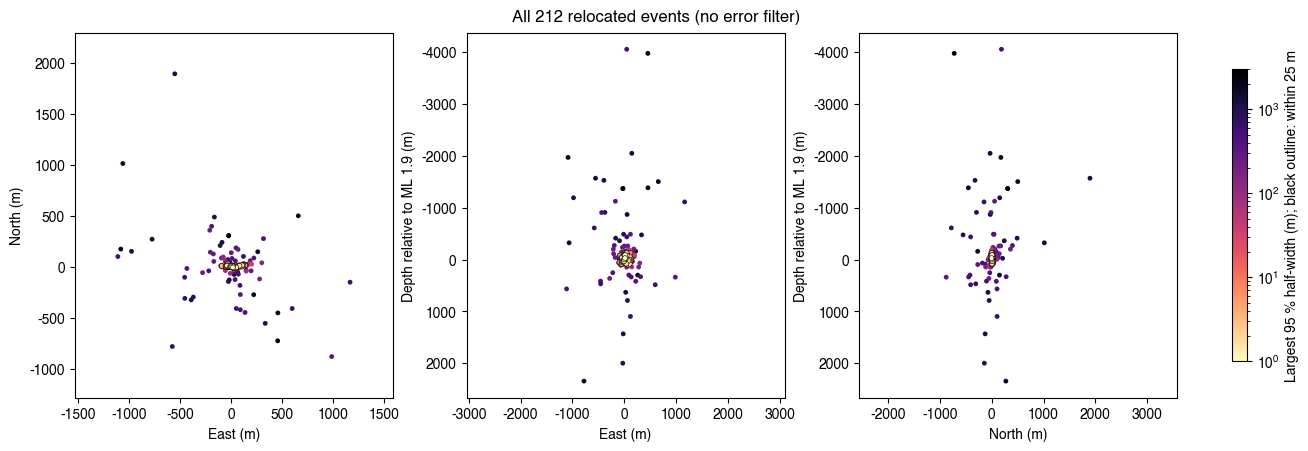

,events,detections,strike,strike_95,dip,dip_95,rms_thickness_m,extent_E,extent_N,extent_Z,depth_before,depth_after
bound_m,,,,,,,,,,,,
10,91,65,269.6,268-272,88.7,87-90,7.1,181,25,209,16,-66
25,101,73,268.7,267-271,88.2,87-90,7.4,210,29,209,16,-62
50,109,81,267.9,266-270,88.1,87-90,8.4,220,35,213,16,-67
100,125,97,88.6,86-92,89.8,87-92,10.2,232,41,228,16,-68
250,151,123,98.5,87-113,78.8,69-88,31.2,261,99,277,14,-64
none,212,184,127.7,92-151,88.2,82-93,177.5,993,784,2134,6,-64


In [10]:
from matplotlib.colors import LogNorm
A = allu.copy(); emax = A[['ex95', 'ey95', 'ez95']].max(axis=1)
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4), layout='constrained')
for a, (x, y, xl, yl) in zip(ax, [('east', 'north', 'East (m)', 'North (m)'), ('east', 'depth_m', 'East (m)', 'Depth relative to ML 1.9 (m)'), ('north', 'depth_m', 'North (m)', 'Depth relative to ML 1.9 (m)')]):
    o = np.argsort(-emax.values)
    sc = a.scatter(A[x].values[o], A[y].values[o], c=emax.values[o], cmap='magma_r', norm=LogNorm(1, 3000), s=12, edgecolor=np.where(A.pass25.values[o], 'black', 'none'), linewidth=0.4)
    a.set_xlabel(xl); a.set_ylabel(yl); a.set_aspect('equal', adjustable='datalim')
    if 'depth' in y: a.invert_yaxis()
fig.colorbar(sc, ax=ax, shrink=0.8, label='Largest 95 % half-width (m); black outline: within 25 m')
fig.suptitle(f'All {len(A)} relocated events (no error filter)'); plt.show()
def sweep_row(bound, n_res=500):
    g = A if bound is None else A[emax <= bound]
    X = g[['east', 'north', 'depth_m']].to_numpy(); pp = plane(X); r_ = np.random.default_rng(20260922)
    bb = [plane(X[r_.integers(0, len(X), len(X))]) for _ in range(n_res)]
    al_ = np.array([b['normal'] * np.sign(b['normal'] @ pp['normal']) for b in bb])
    s_ = (np.degrees(np.arctan2(al_[:, 0], al_[:, 1])) - 90) % 360; s_ = pp['strike'] + ((s_ - pp['strike'] + 180) % 360 - 180); d_ = np.degrees(np.arccos(np.clip(-al_[:, 2], -1, 1)))
    b4_, af_ = g[g.t < t19], g[g.t > t19 + pd.Timedelta(seconds=5)]
    return dict(bound_m='none' if bound is None else bound, events=len(g), detections=int((g.kind == 'detection').sum()), strike=round(pp['strike'], 1),
                strike_95=f'{np.percentile(s_, 2.5):.0f}-{np.percentile(s_, 97.5):.0f}', dip=round(pp['dip'], 1), dip_95=f'{np.percentile(d_, 2.5):.0f}-{np.percentile(d_, 97.5):.0f}',
                rms_thickness_m=round(pp['rms'], 1), extent_E=round(g.east.quantile(.975) - g.east.quantile(.025)), extent_N=round(g.north.quantile(.975) - g.north.quantile(.025)),
                extent_Z=round(g.depth_m.quantile(.975) - g.depth_m.quantile(.025)), depth_before=round(b4_.depth_m.median()), depth_after=round(af_.depth_m.median()))
sweep = pd.DataFrame([sweep_row(b) for b in (10, 25, 50, 100, 250, None)]).set_index('bound_m'); display(sweep)

## Comprehensive summary

In [11]:
summary = pd.DataFrame([
    ('Submitted / relocated (references; detections)', f'{len(inp)} / {len(allu)} ({len(R)}; {len(D)})'),
    ('Condition numbers within 40-80', cnd_ok),
    ('Detections with catalog links (design: 0)', ct_det),
    ('Reference shift vs DL-only relocation, median |dE, dN, dZ| (m)', ', '.join(f'{v:.1f}' for v in ref_shift.loc['50%'])),
    ('25 m rule: references / detections', f'{int(R.pass25.sum())} of {len(R)} / {int(D.pass25.sum())} of {len(D)}'),
    ('Combined 25 m catalog: events; extent E / N / Z (m)', f'{len(G)}; ' + ' / '.join(f'{v:.0f}' for v in ext.values())),
    ('Plane (Haenam method), normal-aligned 95 % strike; dip', f'{p["strike"]:.1f} / {p["dip"]:.1f}; {np.percentile(a_str, 2.5):.0f}-{np.percentile(a_str, 97.5):.0f}; {np.percentile(a_dip, 2.5):.0f}-{np.percentile(a_dip, 97.5):.0f}'),
    ('Median 95 % half-widths E / N / Z: references; detections (m)', ' / '.join(f'{v:.1f}' for v in R[['ex95', 'ey95', 'ez95']].median()) + '; ' + ' / '.join(f'{v:.1f}' for v in D[['ex95', 'ey95', 'ez95']].median())),
    ('No error filter: events; plane; RMS thickness; extent E / N / Z (m)', f'{sweep.loc["none", "events"]}; {sweep.loc["none", "strike"]} / {sweep.loc["none", "dip"]}; {sweep.loc["none", "rms_thickness_m"]}; {sweep.loc["none", "extent_E"]} / {sweep.loc["none", "extent_N"]} / {sweep.loc["none", "extent_Z"]}'),
], columns=['quantity', 'value'])
display(summary)

,quantity,value
0,Submitted / relocated (references; detections),235 / 212 (28; 184)
1,Condition numbers within 40-80,True
2,Detections with catalog links (design: 0),0
3,"Reference shift vs DL-only relocation, median ...","1.4, 1.1, 1.0"
4,25 m rule: references / detections,28 of 28 / 73 of 184
5,Combined 25 m catalog: events; extent E / N / ...,101; 210 / 29 / 209
6,"Plane (Haenam method), normal-aligned 95 % str...",268.7 / 88.2; 267-271; 87-90
7,Median 95 % half-widths E / N / Z: references;...,1.8 / 1.3 / 1.2; 16.6 / 17.1 / 75.9
8,No error filter: events; plane; RMS thickness;...,212; 127.7 / 88.2; 177.5; 993 / 784 / 2134
